# 4. Modelos de aprendizaje supervisado

**Objetivo:** entrenar y comparar 11 algoritmos de clasificación para predecir la supervivencia.

| # | Modelo |
|---|---|
| 1 | Regresión Logística |
| 2 | Support Vector Classifier |
| 3 | Decision Tree Classifier |
| 4 | KNeighbors Classifier |
| 5 | Random Forest Classifier |
| 6 | AdaBoost Classifier |
| 7 | Gradient Boosting Classifier |
| 8 | CatBoost Classifier |
| 9 | XGBoost Classifier |
| 10 | LightGBM Classifier |
| 11 | Gaussian Naive Bayes |

**Métricas:**
- **Exactitud (accuracy):** % total de aciertos.
- **Precisión (precision):** de los que el modelo dice que sobreviven, cuántos realmente sobrevivieron.
- **Sensibilidad (recall):** de los que sobrevivieron, cuántos detecta el modelo.
- **Especificidad:** de los que NO sobrevivieron, cuántos detecta el modelo.
- **AUC-ROC:** capacidad de separar ambas clases en todos los umbrales (1 = perfecto, 0.5 = azar).

**Metodología:** partición estratificada 80/20. En el 80 % se hace **validación cruzada estratificada de 5 pliegues** (estimación robusta) y el 20 % se reserva como **conjunto de prueba** que el modelo nunca ve al entrenar.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, make_scorer, roc_curve, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42
os.makedirs("results", exist_ok=True)

## 4.1 Datos y partición

In [2]:
df = pd.read_csv("data/titanic_features.csv")
X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("Tasa de supervivencia train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Entrenamiento: (712, 35)  Prueba: (179, 35)
Tasa de supervivencia train/test: 0.383 / 0.385


## 4.2 Definición de modelos
Los modelos sensibles a la escala (Logística, SVC, KNN) van dentro de un *pipeline* con `StandardScaler`, que se ajusta **solo** con los datos de entrenamiento de cada pliegue.

In [3]:
escalar = lambda m: make_pipeline(StandardScaler(), m)

modelos = {
    "Regresión Logística": escalar(LogisticRegression(max_iter=2000, random_state=SEED)),
    "SVC":                 escalar(SVC(probability=True, random_state=SEED)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "KNeighbors":          escalar(KNeighborsClassifier(n_neighbors=7)),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED, n_jobs=-1),
    "AdaBoost":            AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED),
    "CatBoost":            CatBoostClassifier(iterations=400, depth=5, learning_rate=0.05, verbose=0,
                                              random_seed=SEED, allow_writing_files=False),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9,
                                         colsample_bytree=0.9, eval_metric="logloss", random_state=SEED),
    "LightGBM":            LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, num_leaves=15,
                                          random_state=SEED, verbose=-1),
    "GaussianNB":          GaussianNB(),
}
len(modelos)

11

## 4.3 Validación cruzada (5 pliegues)

In [4]:
especificidad = make_scorer(recall_score, pos_label=0)
scoring = {
    "exactitud": "accuracy",
    "precision": "precision",
    "sensibilidad": "recall",
    "especificidad": especificidad,
    "auc_roc": "roc_auc",
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

filas_cv = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    fila = {"modelo": nombre}
    for m in scoring:
        fila[f"{m}_cv"] = r[f"test_{m}"].mean()
        fila[f"{m}_cv_std"] = r[f"test_{m}"].std()
    filas_cv.append(fila)

res_cv = pd.DataFrame(filas_cv).set_index("modelo").sort_values("auc_roc_cv", ascending=False)
res_cv[[c for c in res_cv.columns if not c.endswith("_std")]].round(4)

,exactitud_cv,precision_cv,sensibilidad_cv,especificidad_cv,auc_roc_cv
modelo,,,,,
Gradient Boosting,0.8203,0.7943,0.7253,0.8794,0.8953
CatBoost,0.8273,0.8028,0.7364,0.8840,0.8942
XGBoost,0.8216,0.7926,0.7290,0.8794,0.8936
Random Forest,0.8343,0.8084,0.7508,0.8863,0.8897
LightGBM,0.8301,0.8138,0.7290,0.8931,0.8896
AdaBoost,0.8132,0.7645,0.7474,0.8543,0.8773
SVC,0.8104,0.7589,0.7507,0.8476,0.8646
Regresión Logística,0.8161,0.7726,0.7475,0.8590,0.8629
Decision Tree,0.8259,0.7903,0.7547,0.8703,0.8541


## 4.4 Evaluación en el conjunto de prueba

In [5]:
filas_test, probas = [], {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    probas[nombre] = proba
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas_test.append({
        "modelo": nombre,
        "exactitud_test": accuracy_score(y_test, pred),
        "precision_test": precision_score(y_test, pred),
        "sensibilidad_test": recall_score(y_test, pred),
        "especificidad_test": tn / (tn + fp),
        "auc_roc_test": roc_auc_score(y_test, proba),
    })

res_test = pd.DataFrame(filas_test).set_index("modelo")
resultados = res_cv.join(res_test).sort_values("auc_roc_cv", ascending=False)
tabla = resultados[["exactitud_cv", "auc_roc_cv", "auc_roc_cv_std",
                    "exactitud_test", "precision_test", "sensibilidad_test", "especificidad_test", "auc_roc_test"]].round(4)
tabla.to_csv("results/comparacion_modelos.csv")
tabla.style.background_gradient(cmap="Greens", subset=["auc_roc_cv", "exactitud_test", "auc_roc_test"]).format("{:.4f}")

,exactitud_cv,auc_roc_cv,auc_roc_cv_std,exactitud_test,precision_test,sensibilidad_test,especificidad_test,auc_roc_test
modelo,,,,,,,,
Gradient Boosting,0.8203,0.8953,0.0132,0.8101,0.7869,0.6957,0.8818,0.8505
CatBoost,0.8273,0.8942,0.0197,0.7933,0.7581,0.6812,0.8636,0.8462
XGBoost,0.8216,0.8936,0.0160,0.8045,0.7742,0.6957,0.8727,0.8356
Random Forest,0.8343,0.8897,0.0204,0.7989,0.7705,0.6812,0.8727,0.8419
LightGBM,0.8301,0.8896,0.0131,0.7877,0.7460,0.6812,0.8545,0.8165
AdaBoost,0.8132,0.8773,0.0180,0.8045,0.7500,0.7391,0.8455,0.8388
SVC,0.8104,0.8646,0.0294,0.7989,0.7200,0.7826,0.8091,0.8506
Regresión Logística,0.8161,0.8629,0.0300,0.8268,0.7794,0.7681,0.8636,0.8672
Decision Tree,0.8259,0.8541,0.0393,0.8101,0.7333,0.7971,0.8182,0.8165


## 4.5 Visualización comparativa

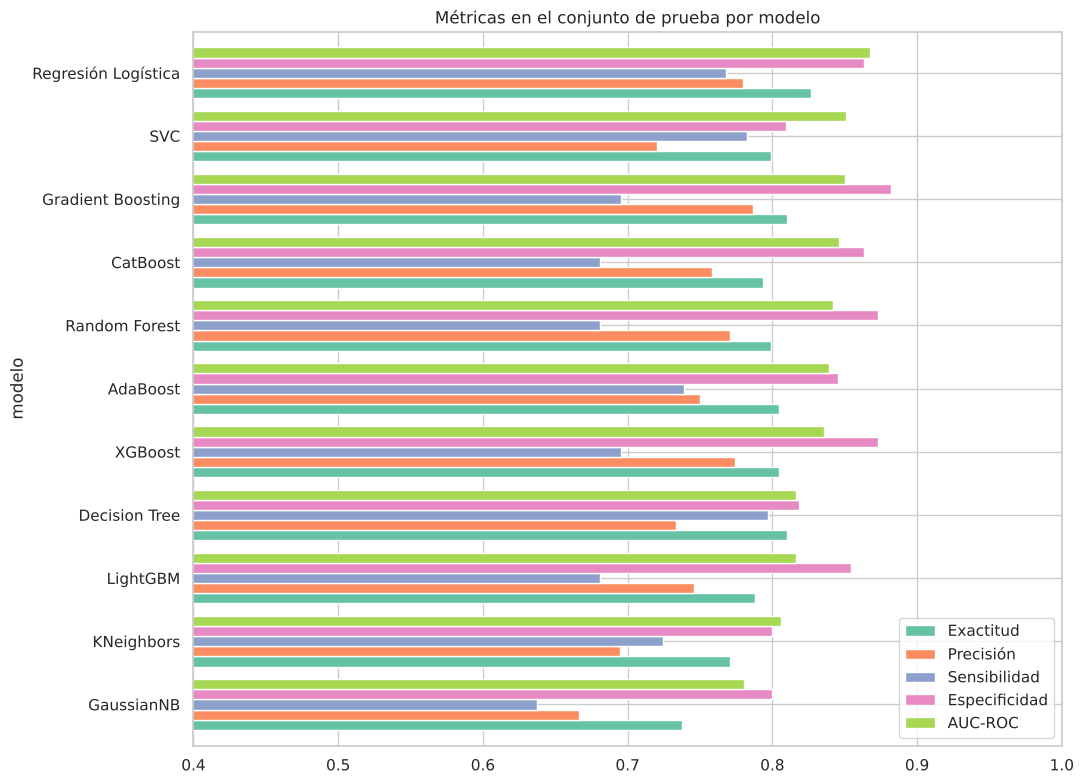

In [6]:
metricas = ["exactitud_test", "precision_test", "sensibilidad_test", "especificidad_test", "auc_roc_test"]
ax = tabla[metricas].sort_values("auc_roc_test").plot.barh(figsize=(11, 8), width=0.8)
ax.set_xlim(0.4, 1.0)
ax.set_title("Métricas en el conjunto de prueba por modelo")
ax.legend(["Exactitud", "Precisión", "Sensibilidad", "Especificidad", "AUC-ROC"], loc="lower right")
plt.tight_layout(); plt.show()

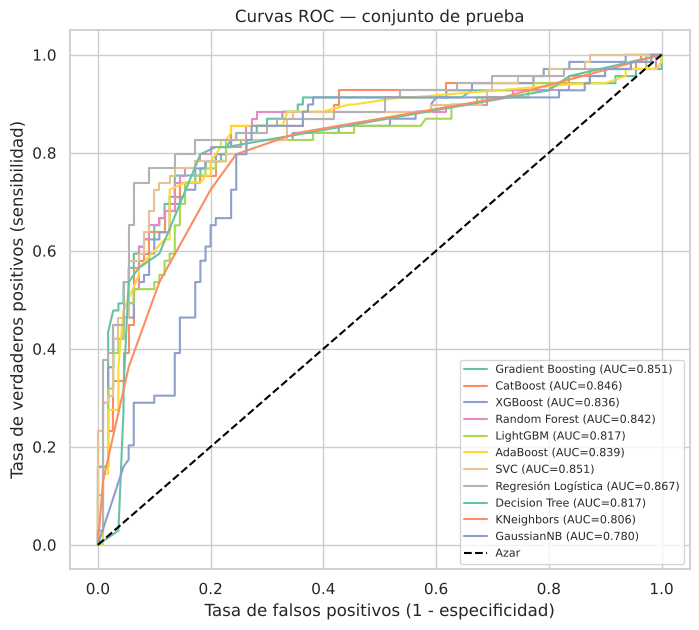

In [7]:
plt.figure(figsize=(8, 7))
for nombre in tabla.index:
    fpr, tpr, _ = roc_curve(y_test, probas[nombre])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={tabla.loc[nombre, 'auc_roc_test']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
plt.ylabel("Tasa de verdaderos positivos (sensibilidad)")
plt.title("Curvas ROC — conjunto de prueba")
plt.legend(fontsize=8, loc="lower right")
plt.show()

## 4.6 Selección del mejor modelo

**Criterio:** el AUC-ROC promedio de la **validación cruzada** es la medida principal, porque promedia 5 particiones y es menos sensible a la suerte de una sola partición de 179 pasajeros. Se toma en cuenta también la estabilidad (desviación estándar) y se confirma con el desempeño en prueba.

Se puntúa cada modelo como: `AUC_cv − desviación_cv`, para premiar a los modelos que son buenos **y** consistentes.

In [8]:
resultados["puntaje"] = resultados["auc_roc_cv"] - resultados["auc_roc_cv_std"]
ranking = resultados.sort_values("puntaje", ascending=False)
mejor = ranking.index[0]

print("Ranking (AUC_cv - std):")
print(ranking[["auc_roc_cv", "auc_roc_cv_std", "puntaje", "auc_roc_test", "exactitud_test"]].round(4))
print(f"\n>>> Mejor modelo: {mejor}")

with open("results/mejor_modelo.txt", "w", encoding="utf-8") as f:
    f.write(mejor)

Ranking (AUC_cv - std):
                     auc_roc_cv  auc_roc_cv_std  puntaje  auc_roc_test  \
modelo                                                                   
Gradient Boosting        0.8953          0.0132   0.8821        0.8505   
XGBoost                  0.8936          0.0160   0.8776        0.8356   
LightGBM                 0.8896          0.0131   0.8765        0.8165   
CatBoost                 0.8942          0.0197   0.8746        0.8462   
Random Forest            0.8897          0.0204   0.8693        0.8419   
AdaBoost                 0.8773          0.0180   0.8594        0.8388   
SVC                      0.8646          0.0294   0.8352        0.8506   
Regresión Logística      0.8629          0.0300   0.8330        0.8672   
KNeighbors               0.8466          0.0202   0.8264        0.8059   
Decision Tree            0.8541          0.0393   0.8148        0.8165   
GaussianNB               0.8157          0.0368   0.7789        0.7805   

             

               precision    recall  f1-score   support

No sobrevivió       0.82      0.88      0.85       110
   Sobrevivió       0.79      0.70      0.74        69

     accuracy                           0.81       179
    macro avg       0.80      0.79      0.79       179
 weighted avg       0.81      0.81      0.81       179



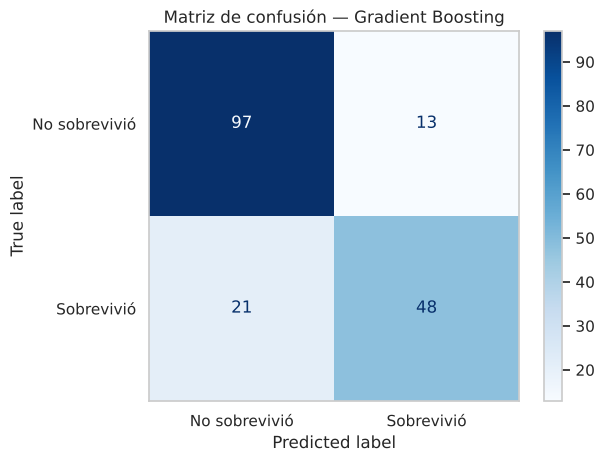

In [9]:
modelo_final = modelos[mejor]
pred = modelo_final.predict(X_test)
print(classification_report(y_test, pred, target_names=["No sobrevivió", "Sobrevivió"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No sobrevivió", "Sobrevivió"], cmap="Blues")
plt.title(f"Matriz de confusión — {mejor}")
plt.grid(False); plt.show()

## 4.7 Interpretación: ¿qué variables influyen más?
Se usa **importancia por permutación** en el conjunto de prueba: se desordena una variable a la vez y se mide cuánto cae el AUC. Funciona igual para cualquier modelo y refleja el efecto real en la predicción.

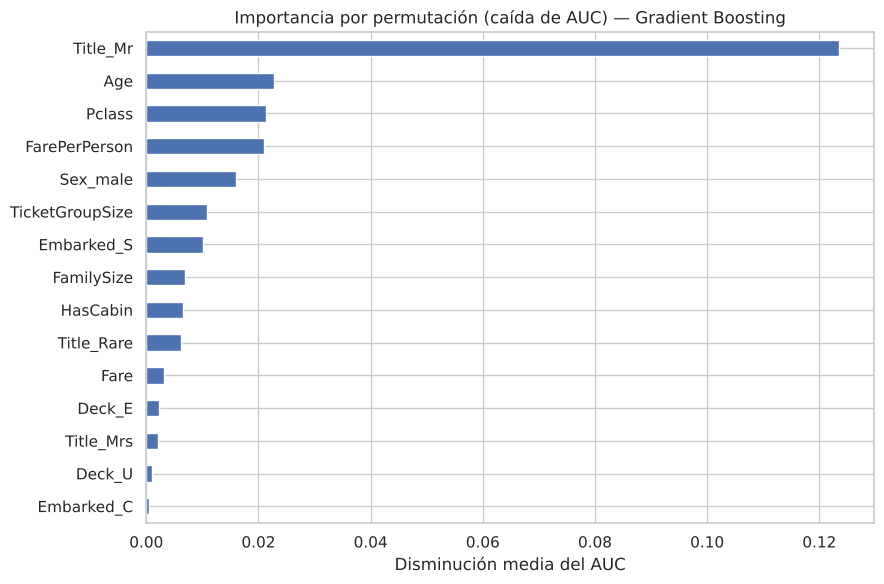

Title_Mr           0.1236
Age                0.0228
Pclass             0.0214
FarePerPerson      0.0210
Sex_male           0.0160
TicketGroupSize    0.0109
Embarked_S         0.0101
FamilySize         0.0070
HasCabin           0.0066
Title_Rare         0.0062
dtype: float64

In [10]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.to_csv("results/importancia_variables.csv", header=["importancia_auc"])

imp.head(15).sort_values().plot.barh(figsize=(9, 6), color="#4c72b0")
plt.title(f"Importancia por permutación (caída de AUC) — {mejor}")
plt.xlabel("Disminución media del AUC")
plt.tight_layout(); plt.show()
imp.head(10).round(4)

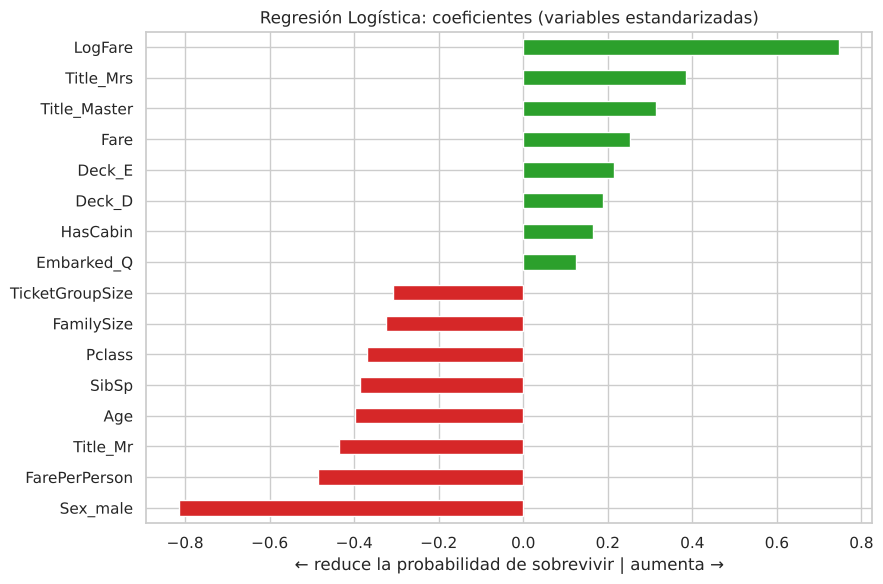

In [11]:
# Comparación: coeficientes de la Regresión Logística (modelo interpretable de referencia)
logit = modelos["Regresión Logística"][-1]
coefs = pd.Series(logit.coef_[0], index=X_train.columns).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(9, 6),
    color=["#d62728" if v < 0 else "#2ca02c" for v in pd.concat([coefs.head(8), coefs.tail(8)])])
plt.title("Regresión Logística: coeficientes (variables estandarizadas)")
plt.xlabel("← reduce la probabilidad de sobrevivir | aumenta →")
plt.tight_layout(); plt.show()

## 4.8 Conclusiones

**Resultados (semilla 42):**

1. **Mejor modelo: Gradient Boosting.** Tiene el AUC-ROC de validación cruzada más alto (**0.895**) con la menor variación entre pliegues (±0.013). En prueba logra **81.0 % de exactitud**, AUC **0.851**, precisión 0.79, sensibilidad 0.70 y especificidad 0.88.
2. Los modelos de **ensamble basados en árboles** (Gradient Boosting, CatBoost, XGBoost, Random Forest, LightGBM) ocupan los 5 primeros lugares en validación cruzada (AUC 0.89–0.90): capturan relaciones no lineales como "mujer **y** primera clase" o el efecto del tamaño de familia.
3. La **Regresión Logística** obtuvo el mejor AUC en prueba (0.867), pero en validación cruzada queda por debajo (0.863 ± 0.030). Su buen resultado en prueba depende más de esa partición en particular; aun así es una alternativa simple e interpretable muy competitiva.
4. **GaussianNB** es el más débil (AUC 0.78) porque supone variables independientes, y aquí están muy correlacionadas (sexo–título, clase–tarifa–cabina).
5. En todos los modelos la **especificidad (~0.80–0.88) supera a la sensibilidad (~0.64–0.80)**: es más fácil identificar a quien no sobrevivió (la clase mayoritaria) que a quien sí.

**Variables más influyentes (permutación, Gradient Boosting):** `Title_Mr` es por mucho la más importante, porque resume ser **hombre adulto**. Le siguen la **edad**, la **clase**, la **tarifa por persona**, el **sexo** y el **tamaño del grupo del boleto**. Esto confirma el EDA: el protocolo de "mujeres y niños primero" y el nivel socioeconómico determinaron la supervivencia.

**Siguiente paso:** `5_pipeline.ipynb` (ajustar los hiperparámetros del mejor modelo y empaquetar todo el proceso).